In [1]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectFromModel
from scipy.stats import ttest_rel
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
# Ruta del archivo
# Ruta de Colab primero
BASE_DATA_DIR = "/content/drive/MyDrive/TEG02-2025Arellano/Data"
if not os.path.exists(BASE_DATA_DIR):
    # Fallback a ruta local
    BASE_DATA_DIR = r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos"
    
print(f"Usando BASE_DATA_DIR: {BASE_DATA_DIR}")

dataset_mode = "lite"  # Cambiar a "full" si querés analizar el otro

file_map = {
    "lite": "matches_final_model_clean2.csv",
    "full": "matches_final_model_full2.csv",
}

file_path = os.path.join(BASE_DATA_DIR, file_map[dataset_mode])
# Cargar datos
df = pd.read_csv(file_path)
print(f"Modo: {dataset_mode} | {df.shape[0]} filas x {df.shape[1]} columnas")

Usando BASE_DATA_DIR: C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos
Modo: lite | 35629 filas x 53 columnas


In [3]:
# =============================================================================
# NOTA
# =============================================================================
# Este notebook realiza análisis exploratorio de variables sobre todo el
# dataset usando validación cruzada con KFold(shuffle=True). Su objetivo es
# diagnosticar el poder predictivo individual y conjunto de las features,
# NO reportar el rendimiento final del ensamble.
#
# Las métricas de accuracy/F1 aquí obtenidas NO son comparables con las del
# pipeline principal (Módulo 7), que usa un split cronológico estricto 70/30
# sin shuffle, evaluado sobre el conjunto de prueba temporal.
#
# Las decisiones de inclusión/exclusión de variables (ej. home_OccRat) se
# basan en la significancia estadística de los t-tests pareados de este
# notebook, pero el rendimiento final reportado en el manuscrito proviene
# exclusivamente de la corrida guardada del pipeline principal.
# =============================================================================

In [4]:
# -----------------------------------------------------------------------------
# 1. CREAR LA VARIABLE TARGET 'Outcome'
# -----------------------------------------------------------------------------
df['Outcome'] = np.where(df['home_goals'] > df['away_goals'], -1,  # Local gana
                         np.where(df['home_goals'] == df['away_goals'], 0,  # Empate
                                  1))  # Visitante gana

print("\nDistribución del Target (Outcome):")
print(df['Outcome'].value_counts().sort_index())



Distribución del Target (Outcome):
Outcome
-1    15559
 0     9654
 1    10416
Name: count, dtype: int64


In [5]:
# =============================================================================
# DEBUG: EQUIPOS CON DATOS FALTANTES EN travel_km
# =============================================================================

# 1. Filtrar las filas donde 'travel_km' es NaN
mask_nan = df['travel_km'].isna()
df_nan_travel = df[mask_nan]

print(f"🔍 Partidos con 'travel_km' faltante (NaN): {len(df_nan_travel)}")
print(f"   Total de partidos en el dataset: {len(df)}")
print(f"   Porcentaje de datos faltantes: {len(df_nan_travel)/len(df)*100:.2f}%\n")

# 2. Extraer los equipos locales y visitantes de esos partidos
# ¡OJO! Verifica que las columnas se llamen 'home_team' y 'away_team'.
# Si no, cámbialas aquí (ej. 'HomeTeam', 'home_team_name', etc.)
home_teams = df_nan_travel['home_team'].tolist()
away_teams = df_nan_travel['away_team'].tolist()

# 3. Unir ambas listas y eliminar duplicados usando set()
teams_with_nan = list(set(home_teams + away_teams))
teams_with_nan.sort()  # Orden alfabético para mejor lectura

print("📋 LISTA DE EQUIPOS ÚNICOS (sin repetición) CON travel_km NaN:")
print(teams_with_nan)
print(f"\nTotal de equipos únicos afectados: {len(teams_with_nan)}")

# 4. (Opcional) Ver cuántos partidos le faltan a cada equipo específicamente
from collections import Counter
todos_los_equipos = home_teams + away_teams
frecuencia = Counter(todos_los_equipos)

print("\n📊 FRECUENCIA DE FALTANTES POR EQUIPO (Top 10):")
for equipo, count in frecuencia.most_common(10):
    print(f"   {equipo}: {count} partidos")

# 5. (Opcional) Guardar la lista en un archivo .txt para tu anexo de TEG
with open("equipos_con_travel_km_faltante.txt", "w", encoding="utf-8") as f:
    f.write("Lista de equipos únicos con datos faltantes en travel_km:\n")
    for equipo in teams_with_nan:
        f.write(f"{equipo}\n")
print("\n✅ Lista guardada en 'equipos_con_travel_km_faltante.txt'")

🔍 Partidos con 'travel_km' faltante (NaN): 0
   Total de partidos en el dataset: 35629
   Porcentaje de datos faltantes: 0.00%

📋 LISTA DE EQUIPOS ÚNICOS (sin repetición) CON travel_km NaN:
[]

Total de equipos únicos afectados: 0

📊 FRECUENCIA DE FALTANTES POR EQUIPO (Top 10):

✅ Lista guardada en 'equipos_con_travel_km_faltante.txt'


In [6]:
# =============================================================================
# IMPUTACIÓN DE travel_km USANDO DISTANCIA GEODÉSICA (LAT/LON)
# =============================================================================
import pandas as pd
import numpy as np

# 1. Cargar la base de datos de estadios/equipos
stadium_path = r"C:\Users\ruben\Desktop\TEG\EstadiumsDB_normalized.csv"
df_stadiums = pd.read_csv(stadium_path)

print("=== BASE DE ESTADIOS CARGADA ===")
print(f"Columnas disponibles: {df_stadiums.columns.tolist()}")
print(f"Total de equipos en la DB: {len(df_stadiums)}")
print(df_stadiums.head())

# 2. CONFIGURACIÓN: Ajusta estos nombres según las columnas reales de tu CSV
# -------------------------------------------------------------------------
# Cambia estos strings si tu archivo los tiene diferentes
col_equipo = 'Team'          # Columna donde está el nombre del equipo
col_lat = 'Lat'             # Columna de latitud
col_lon = 'Lon'             # Columna de longitud
# -------------------------------------------------------------------------

# 3. Crear un diccionario para búsqueda rápida: {nombre_equipo: (lat, lon)}
# Limpiamos espacios y estandarizamos para evitar errores por espacios extra
df_stadiums['team_clean'] = df_stadiums[col_equipo].str.replace(' ', '').str.strip()
df_stadiums['team_clean'] = df_stadiums['team_clean'].str.lower()  # Para evitar diferencias de mayúsculas

# Diccionario final
coords_dict = df_stadiums.set_index('team_clean').apply(
    lambda row: (row[col_lat], row[col_lon]), axis=1
).to_dict()

print("\n📌 Diccionario de coordenadas creado.")

# 4. Función para limpiar nombres en el dataset principal (quita espacios y pasa a minúsculas)
def clean_team_name(name):
    if pd.isna(name):
        return None
    return str(name).replace(' ', '').strip().lower()

# 5. Aplicar limpieza a las columnas de equipos en df (creamos columnas auxiliares)
df['home_team_clean'] = df['home_team'].apply(clean_team_name)
df['away_team_clean'] = df['away_team'].apply(clean_team_name)

# 6. Mapear lat/lon para cada partido usando las columnas limpias
df['home_lat'] = df['home_team_clean'].map(lambda x: coords_dict.get(x, (np.nan, np.nan))[0])
df['home_lon'] = df['home_team_clean'].map(lambda x: coords_dict.get(x, (np.nan, np.nan))[1])
df['away_lat'] = df['away_team_clean'].map(lambda x: coords_dict.get(x, (np.nan, np.nan))[0])
df['away_lon'] = df['away_team_clean'].map(lambda x: coords_dict.get(x, (np.nan, np.nan))[1])

# 7. Identificar qué equipos de los que necesitamos NO están en el diccionario
mask_nan_travel = df['travel_km'].isna()
equipos_faltantes_home = set(df.loc[mask_nan_travel, 'home_team_clean'])
equipos_faltantes_away = set(df.loc[mask_nan_travel, 'away_team_clean'])
todos_equipos_faltantes = equipos_faltantes_home.union(equipos_faltantes_away)

equipos_sin_coordenada = []
for team in todos_equipos_faltantes:
    if team not in coords_dict:
        equipos_sin_coordenada.append(team)

if equipos_sin_coordenada:
    print("\n⚠️ ALERTA: Los siguientes equipos NO tienen coordenadas en la DB de estadios:")
    print(equipos_sin_coordenada)
    print("Revisa que el nombre en tu archivo 'EstadiumsDB_normalized.csv' coincida.")
    print("Si el error es por tildes o espacios, corrígelo manualmente en el CSV.")
else:
    print("\n✅ Todos los equipos con travel_km faltante tienen coordenadas disponibles.")

from math import radians, sin, cos, sqrt, atan2

# 8. Calcular distancia geodésica (en kilómetros) solo para las filas con NaN
def haversine(lat1, lon1, lat2, lon2):
    R = 6371  # Radio de la Tierra en km
    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = sin(dlat/2)**2 + cos(lat1) * cos(lat2) * sin(dlon/2)**2
    c = 2 * atan2(sqrt(a), sqrt(1-a))
    return R * c

# Aplicamos solo a las filas que tienen travel_km faltante
df.loc[mask_nan_travel, 'travel_km_imputed'] = df.loc[mask_nan_travel].apply(lambda row: haversine(row['home_lat'], row['home_lon'], row['away_lat'], row['away_lon']), axis=1)

# 9. Rellenar los NaN originales con el valor imputado
cantidad_imputada = df.loc[mask_nan_travel, 'travel_km_imputed'].notna().sum()
df['travel_km'] = df['travel_km'].fillna(df['travel_km_imputed'])

print(f"\n✅ Se imputaron {cantidad_imputada} valores de 'travel_km' mediante distancia geodésica.")

# 10. Verificación final: ¿Cuántos NaN quedan?
nan_restantes = df['travel_km'].isna().sum()
print(f"📊 Valores faltantes restantes en 'travel_km': {nan_restantes}")

if nan_restantes > 0:
    print("⚠️ Aún quedan NaN. Revisa los equipos sin coordenadas mencionados arriba.")
else:
    print("🎉 'travel_km' está completamente imputado. ¡Ya no hay NaN!")

# (Opcional) Eliminar columnas auxiliares si no las necesitas para el modelo
columnas_auxiliares = ['home_team_clean', 'away_team_clean', 
                       'home_lat', 'home_lon', 'away_lat', 'away_lon', 'travel_km_imputed']
# Si quieres limpiar el dataframe, descomenta la siguiente línea:
df.drop(columns=columnas_auxiliares, inplace=True)

=== BASE DE ESTADIOS CARGADA ===
Columnas disponibles: ['Country', 'Team', 'Lat', 'Lon', 'Capacity', 'Height', 'Assist_1718', 'Assist_1819', 'Assist_1920', 'Assist_2021', 'Assist_2122', 'Assist_2223', 'Assist_2324', 'Assist_2425']
Total de equipos en la DB: 436
   Country         Team      Lat     Lon  Capacity  Height  Assist_1718  \
0  England      Arsenal  51.5549 -0.1084   60338.0    50.0      59323.0   
1  England   AstonVilla  52.5091 -1.8847   42790.0   105.0          NaN   
2  England  Bournemouth  50.7352 -1.8383   11700.0    35.0      10640.0   
3  England    Brentford  51.4862 -0.2888   17250.0     6.0          NaN   
4  England     Brighton  50.8618 -0.0837   30750.0    55.0      30402.0   

   Assist_1819  Assist_1920  Assist_2021  Assist_2122  Assist_2223  \
0      59899.0      60279.0       6000.0      59811.0      60191.0   
1          NaN      41661.0       1000.0      41681.0      41707.0   
2      10532.0      10510.0          NaN          NaN      10307.0   
3      

In [7]:
# -----------------------------------------------------------------------------
# 2. SEPARAR PREDICTORES (X) Y TARGET (Y)
# -----------------------------------------------------------------------------
# Eliminamos las columnas que definen el resultado (fuga de datos) y el target
columnas_a_excluir = ['home_goals', 'away_goals', 'Outcome', 'match_id_new', 'match_date_from_id', 'Competition', 'year_from_id', 'month_from_id', 'home_Goals', 'away_Goals', 'home_team_id', 'away_team_id', 'home_team', 'away_team', 'home_goals_r5', 'home_Gcon_r5', 'home_goals_r10', 'home_Gcon_r10', 'home_goals_r20', 'home_Gcon_r20', 'home_goals_r30', 'home_Gcon_r30', 'home_goals_home_r5', 'home_Gcon_home_r5', 'home_goals_home_r10', 'home_Gcon_home_r10', 'home_goals_home_r20', 'home_Gcon_home_r20', 'home_goals_home_r30', 'home_Gcon_home_r30', 'away_goals_r5', 'away_Gcon_r5', 'away_goals_r10', 'away_Gcon_r10', 'away_goals_r20', 'away_Gcon_r20', 'away_goals_r30', 'away_Gcon_r30', 'away_goals_away_r5', 'away_Gcon_away_r5', 'away_goals_away_r10', 'away_Gcon_away_r10', 'away_goals_away_r20', 'away_Gcon_away_r20', 'away_goals_away_r30', 'away_Gcon_away_r30']
X = df.drop(columns=columnas_a_excluir)
y = df['Outcome']

print(f"\nPredictores disponibles (X): {X.shape[1]} variables.")
print(f"Ejemplo de predictores: {X.columns[:].tolist()} ...")


Predictores disponibles (X): 8 variables.
Ejemplo de predictores: ['diff_MarketValue', 'travel_km', 'diff_NetSpending', 'diff_temperature_2m', 'diff_PiO2', 'home_Assist', 'diff_Foreign', 'home_OccRat'] ...



--- Top 15 predictores con mayor correlación (Spearman) con Outcome ---
diff_MarketValue       0.262686
home_Assist            0.106416
diff_Foreign           0.055585
home_OccRat            0.047153
diff_NetSpending       0.046613
travel_km              0.036124
diff_temperature_2m    0.008319
diff_PiO2              0.008045
dtype: float64

>>> home_OccRat está en la posición #4 (correlación = 0.0472)
>>> travel_km está en la posición #6 (correlación = 0.0361)


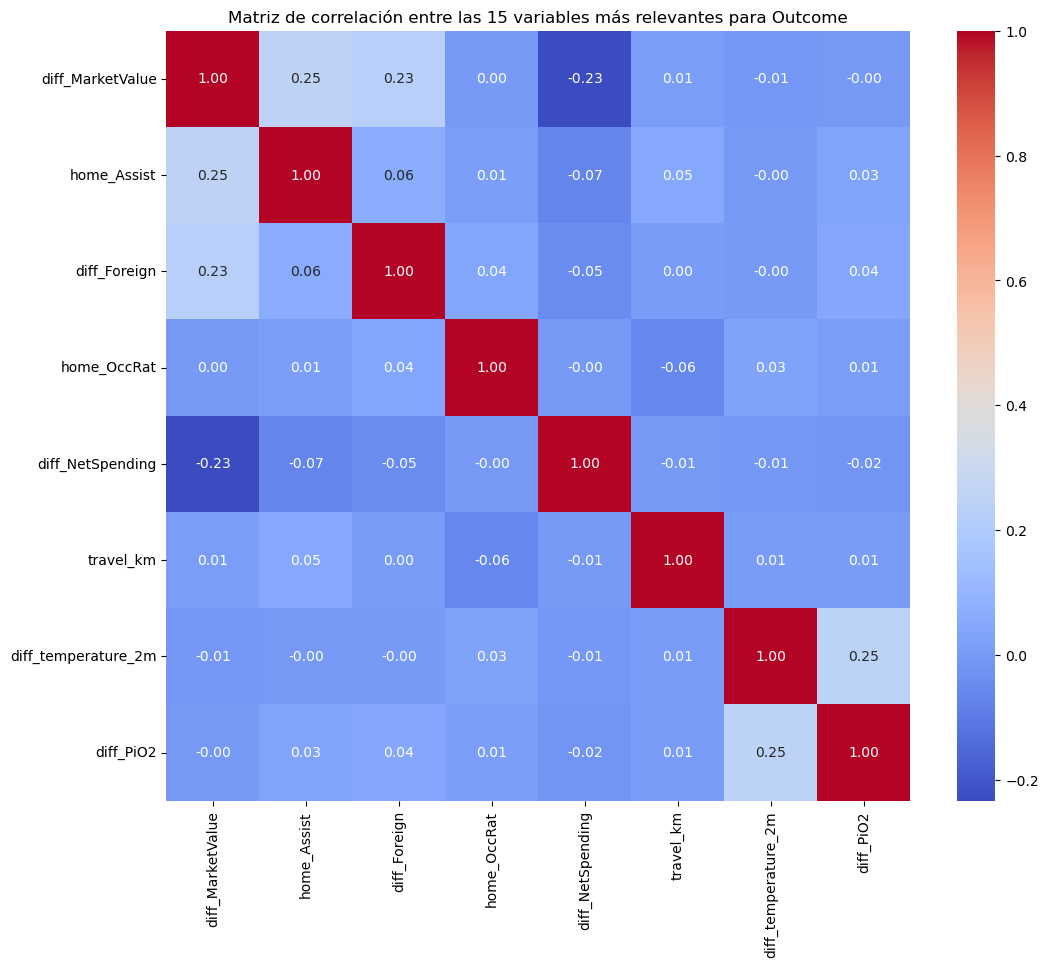

In [8]:
# =============================================================================
# CELDA 2: CORRELACIÓN DE CADA PREDICTOR CON EL TARGET (Outcome)
# =============================================================================
from scipy.stats import spearmanr

# Calcular correlación de Spearman de cada columna con 'Outcome'
corr_dict = {}
for col in X.columns:
    corr, _ = spearmanr(X[col], y)
    corr_dict[col] = abs(corr)  # Usamos el valor absoluto para rankear fuerza

corr_series = pd.Series(corr_dict).sort_values(ascending=False)
print("\n--- Top 15 predictores con mayor correlación (Spearman) con Outcome ---")
print(corr_series.head(15))

# Ubicación específica de home_OccRat y travel_km
if 'home_OccRat' in corr_series.index:
    pos_home = list(corr_series.index).index('home_OccRat') + 1
    print(f"\n>>> home_OccRat está en la posición #{pos_home} (correlación = {corr_series['home_OccRat']:.4f})")

if 'travel_km' in corr_series.index:
    pos_travel = list(corr_series.index).index('travel_km') + 1
    print(f">>> travel_km está en la posición #{pos_travel} (correlación = {corr_series['travel_km']:.4f})")

# Matriz de calor de las 15 mejores (para ver si son redundantes entre sí)
top_vars = corr_series.head(15).index
plt.figure(figsize=(12, 10))
sns.heatmap(X[top_vars].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Matriz de correlación entre las 15 variables más relevantes para Outcome")
plt.show()

In [9]:
# =============================================================================
# CELDA 3: IMPORTANCIA DE PREDICTORES (RANDOM FOREST Y LOGISTIC CON L1)
# =============================================================================
# A. Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X, y)
importancias_rf = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

print("\n--- Top 15 importancia según Random Forest ---")
print(importancias_rf.head(15))

# B. Regresión Logística con penalización L1 (hace selección automática)
# Estandarizamos porque L1 usa magnitudes de las variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Usamos 'liblinear' o 'saga' para L1
logistic = LogisticRegression(penalty='l1', solver='saga', C=0.1, 
                              multi_class='multinomial', max_iter=1000, random_state=42)
logistic.fit(X_scaled, y)

# Coeficientes (importancia en L1)
coef_l1 = pd.Series(abs(logistic.coef_).mean(axis=0), index=X.columns)  # Promedio absoluto entre clases
coef_l1_seleccionados = coef_l1[coef_l1 > 0].sort_values(ascending=False)

print("\n--- Variables seleccionadas por L1 (coeficiente promedio > 0) ---")
print(coef_l1_seleccionados)

# Verificar posiciones de las candidatas
if 'home_OccRat' in importancias_rf.index:
    pos_rf_home = list(importancias_rf.index).index('home_OccRat') + 1
    print(f"\n>>> home_OccRat está en posición #{pos_rf_home} según RF.")
if 'travel_km' in importancias_rf.index:
    pos_rf_travel = list(importancias_rf.index).index('travel_km') + 1
    print(f">>> travel_km está en posición #{pos_rf_travel} según RF.")


--- Top 15 importancia según Random Forest ---
diff_MarketValue       0.167823
diff_PiO2              0.143006
travel_km              0.134817
diff_temperature_2m    0.131994
diff_NetSpending       0.117039
home_Assist            0.113590
home_OccRat            0.108673
diff_Foreign           0.083057
dtype: float64


c:\Users\ruben\.conda\envs\teg\lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(



--- Variables seleccionadas por L1 (coeficiente promedio > 0) ---
diff_MarketValue       0.189457
home_Assist            0.061714
travel_km              0.021859
diff_PiO2              0.013875
diff_NetSpending       0.005637
home_OccRat            0.003129
diff_temperature_2m    0.002269
diff_Foreign           0.001110
dtype: float64

>>> home_OccRat está en posición #7 según RF.
>>> travel_km está en posición #3 según RF.


In [10]:
# =============================================================================
# CELDA 4: VALIDACIÓN CRUZADA - ¿home_OccRat o travel_km?
# =============================================================================
from sklearn.metrics import make_scorer, accuracy_score, f1_score

def evaluar_clasificador(X_sub, y, cv=10):
    """Evalúa RandomForest con CV y devuelve Accuracy y F1-macro de test."""
    modelo = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
    kf = KFold(n_splits=cv, shuffle=True, random_state=42)
    scoring = {
        'accuracy': 'accuracy',
        'f1_macro': make_scorer(f1_score, average='macro')
    }
    resultados = cross_validate(modelo, X_sub, y, cv=kf, scoring=scoring,
                                return_train_score=True)
    return resultados

# Configuraciones
# 1. Todas las variables (modelo base)
res_todas = evaluar_clasificador(X, y)

# 2. Sin home_OccRat
X_sin_home = X.drop(columns=['home_OccRat'])
res_sin_home = evaluar_clasificador(X_sin_home, y)

# 3. Sin travel_km
X_sin_travel = X.drop(columns=['travel_km'])
res_sin_travel = evaluar_clasificador(X_sin_travel, y)

# Mostrar resultados
print("\n=== COMPARATIVA DE RENDIMIENTO (Accuracy) ===")
print(f"Todas las vars:      {res_todas['test_accuracy'].mean():.4f} ± {res_todas['test_accuracy'].std():.4f}")
print(f"Sin home_OccRat:     {res_sin_home['test_accuracy'].mean():.4f} ± {res_sin_home['test_accuracy'].std():.4f}")
print(f"Sin travel_km:       {res_sin_travel['test_accuracy'].mean():.4f} ± {res_sin_travel['test_accuracy'].std():.4f}")

print("\n=== COMPARATIVA DE RENDIMIENTO (F1-macro) ===")
print(f"Todas las vars:      {res_todas['test_f1_macro'].mean():.4f} ± {res_todas['test_f1_macro'].std():.4f}")
print(f"Sin home_OccRat:     {res_sin_home['test_f1_macro'].mean():.4f} ± {res_sin_home['test_f1_macro'].std():.4f}")
print(f"Sin travel_km:       {res_sin_travel['test_f1_macro'].mean():.4f} ± {res_sin_travel['test_f1_macro'].std():.4f}")

# Pruebas t pareadas (comparar con el modelo "todas")
from scipy.stats import ttest_rel

# Home_OccRat
t_acc_h, p_acc_h = ttest_rel(res_todas['test_accuracy'], res_sin_home['test_accuracy'])
t_f1_h, p_f1_h = ttest_rel(res_todas['test_f1_macro'], res_sin_home['test_f1_macro'])

# Travel_km
t_acc_t, p_acc_t = ttest_rel(res_todas['test_accuracy'], res_sin_travel['test_accuracy'])
t_f1_t, p_f1_t = ttest_rel(res_todas['test_f1_macro'], res_sin_travel['test_f1_macro'])

print("\n=== SIGNIFICANCIA ESTADÍSTICA (p-valores vs modelo 'Todas') ===")
print(f"Quitar home_OccRat -> Accuracy: p={p_acc_h:.4f} | F1: p={p_f1_h:.4f}")
print(f"Quitar travel_km   -> Accuracy: p={p_acc_t:.4f} | F1: p={p_f1_t:.4f}")

# Conclusión automática
print("\n--- CONCLUSIÓN PARA EL TEG ---")
if p_acc_h < 0.05 and res_todas['test_accuracy'].mean() > res_sin_home['test_accuracy'].mean():
    print("✓ home_OccRat APORTA significativamente al modelo (no debe quitarse).")
else:
    print("✗ home_OccRat NO aporta significativamente; podría eliminarse.")

if p_acc_t < 0.05 and res_todas['test_accuracy'].mean() > res_sin_travel['test_accuracy'].mean():
    print("✓ travel_km APORTA significativamente al modelo (no debe quitarse).")
else:
    print("✗ travel_km NO aporta significativamente; podría eliminarse.")
    
# Si ambas aportan, se quedan las dos. Si una no aporta, se descarta objetivamente.


=== COMPARATIVA DE RENDIMIENTO (Accuracy) ===
Todas las vars:      0.4500 ± 0.0098
Sin home_OccRat:     0.4517 ± 0.0094
Sin travel_km:       0.4461 ± 0.0088

=== COMPARATIVA DE RENDIMIENTO (F1-macro) ===
Todas las vars:      0.3906 ± 0.0100
Sin home_OccRat:     0.3911 ± 0.0088
Sin travel_km:       0.3902 ± 0.0074

=== SIGNIFICANCIA ESTADÍSTICA (p-valores vs modelo 'Todas') ===
Quitar home_OccRat -> Accuracy: p=0.4342 | F1: p=0.8886
Quitar travel_km   -> Accuracy: p=0.1701 | F1: p=0.9007

--- CONCLUSIÓN PARA EL TEG ---
✗ home_OccRat NO aporta significativamente; podría eliminarse.
✗ travel_km NO aporta significativamente; podría eliminarse.


In [11]:
# =============================================================================
# CELDA 5: TOP 10 FINAL DE VARIABLES (A PRUEBA DE JURADO)
# =============================================================================
# Ranking combinado: Correlación Spearman + Importancia RF + Coeficiente L1
# Normalizamos para que cada métrica pese igual
norm_corr = (corr_series - corr_series.min()) / (corr_series.max() - corr_series.min())
norm_rf = (importancias_rf - importancias_rf.min()) / (importancias_rf.max() - importancias_rf.min())
norm_l1 = (coef_l1 - coef_l1.min()) / (coef_l1.max() - coef_l1.min())

# Alineamos índices
ranking_final = (norm_corr + norm_rf + norm_l1).sort_values(ascending=False)
top_10_vars = ranking_final.head(15).index.tolist()

print("\n=== TOP 10 VARIABLES SELECCIONADAS (Ranking Consolidado) ===")
for i, var in enumerate(top_10_vars, 1):
    print(f"{i}. {var} (Score: {ranking_final[var]:.3f})")

# Verificar si están las dos candidatas
print("\n--- ¿Están las candidatas en el Top 10? ---")
print(f"home_OccRat: {'SÍ' if 'home_OccRat' in top_10_vars else 'NO'} está.")
print(f"travel_km: {'SÍ' if 'travel_km' in top_10_vars else 'NO'} está.")

# Chequeo de multicolinealidad entre las Top 10
top10_corr = X[top_10_vars].corr().abs()
upper_tri = top10_corr.where(np.triu(np.ones(top10_corr.shape), k=1).astype(bool))
problemas = [(col, row, upper_tri.loc[col, row]) 
             for col in upper_tri.columns 
             for row in upper_tri.index 
             if upper_tri.loc[col, row] > 0.8]

if problemas:
    print("\n⚠️ ALERTA: Pares con alta correlación (>0.8) en el Top 10:")
    for col, row, val in problemas:
        print(f"   {col} vs {row} : {val:.3f}")
    print("   -> Si alguno de estos pares es (home_OccRat, travel_km), podrías quedarte solo con la de mayor score.")
else:
    print("\n✅ No hay correlaciones > 0.8 entre las Top 10. Conjunto estable.")

# Si home_OccRat y travel_km están ambas, pero una tiene menor score, documentarlo.
if 'home_OccRat' in top_10_vars and 'travel_km' in top_10_vars:
    score_home = ranking_final['home_OccRat']
    score_travel = ranking_final['travel_km']
    if score_home > score_travel:
        print(f"\n>>> home_OccRat (score {score_home:.3f}) supera a travel_km (score {score_travel:.3f}) en el ranking. Su inclusión está plenamente justificada.")
    else:
        print(f"\n>>> travel_km (score {score_travel:.3f}) supera a home_OccRat (score {score_home:.3f}) en el ranking. Si solo se pudiera elegir una, sería travel_km.")


=== TOP 10 VARIABLES SELECCIONADAS (Ranking Consolidado) ===
1. diff_MarketValue (Score: 3.000)
2. home_Assist (Score: 1.068)
3. travel_km (Score: 0.831)
4. diff_PiO2 (Score: 0.775)
5. diff_temperature_2m (Score: 0.585)
6. diff_NetSpending (Score: 0.576)
7. home_OccRat (Score: 0.466)
8. diff_Foreign (Score: 0.187)

--- ¿Están las candidatas en el Top 10? ---
home_OccRat: SÍ está.
travel_km: SÍ está.

✅ No hay correlaciones > 0.8 entre las Top 10. Conjunto estable.

>>> travel_km (score 0.831) supera a home_OccRat (score 0.466) en el ranking. Si solo se pudiera elegir una, sería travel_km.
